In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


float_list = ["Durée moyenne du trajet", "Retard moyen des trains en retard au départ", "Retard moyen des trains en retard à l'arrivée","Retard moyen trains en retard > 15 (si liaison concurrencée par vol)","Retard moyen de tous les trains à l'arrivée",
"Retard moyen de tous les trains au départ","Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic","Prct retard pour cause matériel roulant",
"Prct retard pour cause gestion en gare et réutilisation de matériel","Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

int_list = ["Nombre de circulations prévues","Nombre de trains annulés","Nombre de trains en retard à l'arrivée","Nombre de trains en retard au départ","Nombre trains en retard > 30min","Nombre trains en retard > 60min","Nombre trains en retard > 15min"]

check_if_zero = ["Durée moyenne du trajet","Nombre de circulations prévues"]

ignore_zero_columns = ["Nombre de trains annulés", "Nombre de trains en retard à l'arrivée", 
                       "Nombre de trains en retard au départ", "Nombre trains en retard > 30min",
                       "Nombre trains en retard > 60min", "Nombre trains en retard > 15min",
                       "Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic",
                       "Prct retard pour cause matériel roulant","Prct retard pour cause gestion en gare et réutilisation de matériel",
                       "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

# create dataframe and clear row and duplicate row
data = pd.read_csv('project_dataset.csv', on_bad_lines='warn', sep=';')
data.drop(['Commentaire annulations','Commentaire retards au départ',"Commentaire retards à l'arrivée"],axis=1,inplace=True)
data = data.replace(
    ['', ' ', 'NC', 'Non communiqué', 'N/A', '-', 'None', 'NONE', 'nan', 'NaN'],
    np.nan
)


# Strips the strings, replaces spaces and / to -, and formats to year-month-days dates.
data['Date'] = data['Date'].str.strip().str.replace(' ',"-").str.replace('/','-')
data['Date'] = pd.to_datetime(data['Date'], format='mixed')

# Creates year and month dataframes.
YearDf = data['Date'].dt.year
monthDf = data['Date'].dt.month

## change value if case is empty
for element in data:
    if element in float_list or element in int_list:
        data[element] = data[element].astype(str).replace(['', 'NC', 'Non communiqué', 'N/A','-',' '], np.nan)
    else:
        data[element] = data[element].replace('', np.nan)
        data[element] = data[element].replace('NC', np.nan)
        data[element] = data[element].replace('Non communiqué', np.nan)
        data[element] = data[element].replace('N/A', np.nan)
        data[element] = data[element].replace('-', np.nan)

# format line to dataframe
for element in data:
    if element in float_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip().astype(float).round(2)
    elif element in int_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip()
        data[element] = pd.to_numeric(data[element], errors='coerce').fillna(0).astype(int)
    elif element == "Gare de départ" or element == "Gare d'arrivée":
        data[element] = data[element].str.upper().str.replace("SAINT","ST").str.replace("TGV","").str.replace('0', '').str.replace('1', '').str.replace('2', '').str.replace('3', '').str.replace('4', '').str.replace('5', '').str.replace('6', '').str.replace('7', '').str.replace('8', '').str.replace('9', '').str.strip()

# check if the value is 0.0 and drop the row if it is          
for index in check_if_zero:
    data = data[data[index] != 0]

# check all line if it's ok and drop the row if not
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"] + data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard à l'arrivée"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 30min"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 60min"]]

data = data[data["Prct retard pour cause gestion en gare et réutilisation de matériel"]+ data["Prct retard pour causes externes"]
            + data["Prct retard pour cause infrastructure"] + data["Prct retard pour cause gestion trafic"] + data["Prct retard pour cause matériel roulant"] 
            + data["Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"] <= 100.1]


for col in ["Gare de départ", "Gare d'arrivée"]:
    data[col] = data[col].replace({
        '': np.nan,
        'nan': np.nan,
        'NaN': np.nan,
        'None': np.nan,
        'NONE': np.nan
    })

data = data[data['Date'].notna()]

# remove row if lot of 0 in the row

for index, row in data.iterrows():
    count_zero = 0
    count_nan = 0
    suspect_zero = 0
    for col in data.columns:
        if col not in ignore_zero_columns:
            value = str(row[col])
            if value == '0' or value == '0.0':
                count_zero += 1
            if pd.isna(row[col]):
                count_nan += 1
        suspect_zero = count_nan + count_zero
    if suspect_zero > 3:
        data = data.drop(index)

data.drop_duplicates(inplace=True)

# Feature Engineering: Fiabilité de la ligne (Inversée pour que 1 = Parfait)
data['fiabilite de la ligne'] = 1 - (
    (data['Nombre de trains annulés'] + data["Nombre de trains en retard à l'arrivée"]) / 
    data['Nombre de circulations prévues']
)

data["fiabilite de la ligne"] = data['fiabilite de la ligne'].astype(float).round(2)

data["fiabilite de la ligne"] = data["fiabilite de la ligne"].clip(lower=0)

# remove all data if is equals none
for element in data:
    data = data.dropna(subset=[element])
# Create new csv file with cleaned data
data.to_csv('cleaned_dataset.csv', index=False)

In [29]:
##  add cleaned data to a new dataframe and display info
cleaned_data = pd.read_csv('cleaned_dataset.csv')
cleaned_data['Date'] = pd.to_datetime(cleaned_data['Date'], format='ISO8601')
df = cleaned_data


## DOCUMENTATION
This script loads a raw railway dataset (project_dataset.csv) and performs comprehensive data cleaning using pandas.  
It standardizes missing values, reformats dates, converts numerical columns (floats and integers), and harmonizes station names.  
Several consistency checks are applied (removal of impossible values, percentages above 100%, suspicious zeros, duplicates).  
A new feature called "line reliability" is engineered to measure overall performance.  
It is calculated as 1 - (cancelled trains + delayed arrival trains) / planned trains.  
The final cleaned dataset is exported as a new file: cleaned_dataset.csv.

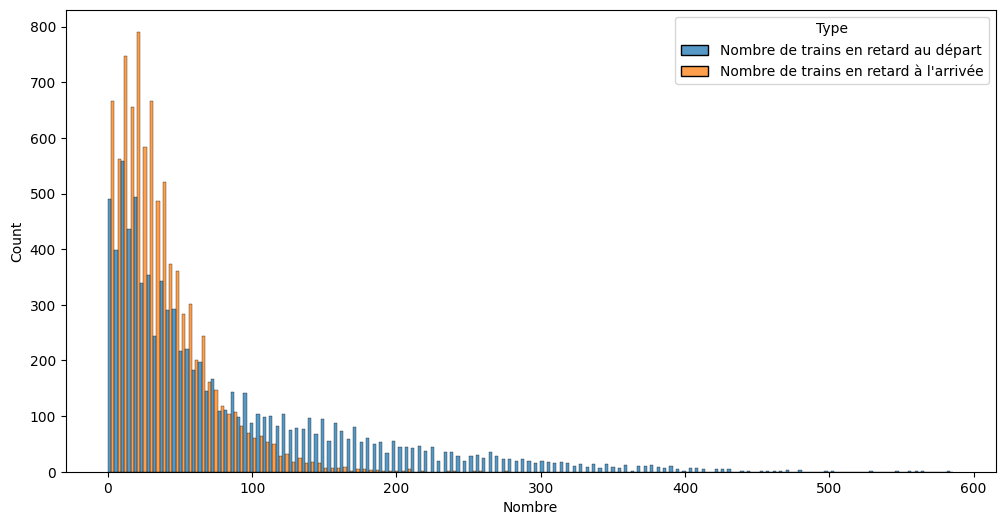

In [30]:
plt.figure(figsize=(12,6))
plot_data = cleaned_data.melt(
    value_vars=[
        "Nombre de trains en retard au départ",
        "Nombre de trains en retard à l'arrivée"
    ],
    var_name="Type",
    value_name="Nombre"
)

# Single histplot with hue
sns.histplot(
    data=plot_data,
    x="Nombre",
    hue="Type",
    multiple="dodge"
)
plt.show()

<Axes: >

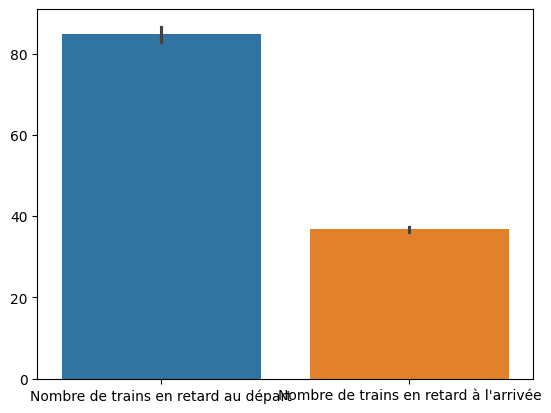

In [31]:
sns.barplot(data = cleaned_data[["Nombre de trains en retard au départ","Nombre de trains en retard à l'arrivée"]] )


In [32]:
total_departure_delays = cleaned_data["Nombre de trains en retard au départ"].sum()
total_arrival_delays = cleaned_data["Nombre de trains en retard à l'arrivée"].sum()
total_trains = cleaned_data["Nombre de circulations prévues"].sum()
total_trains_canceled = cleaned_data["Nombre de trains annulés"].sum()
total_trains_ok = total_trains - total_trains_canceled - total_departure_delays - total_arrival_delays
total_trains_not_ok = total_trains - total_trains_ok
print("Il y a",total_trains_ok,"trains corrects pour",total_trains_not_ok,"trains pas corrects.")
print(round((total_trains_ok / total_trains)*100),"%","des trains performent correctement.")
print(round(((total_arrival_delays + total_departure_delays)/ total_trains)*100),"%","des trains sont en retards.")


mean_delays_departure = cleaned_data['Retard moyen des trains en retard au départ'].mean()
mean_delays_arrival = cleaned_data["Retard moyen des trains en retard à l'arrivée"].mean()
mean_delays_total_departure = cleaned_data['Retard moyen de tous les trains au départ'].mean()
mean_delays_total_arrival = cleaned_data["Retard moyen de tous les trains à l'arrivée"].mean()
print("Moyenne du temps de retard  :",(mean_delays_departure + mean_delays_arrival)/2, "min")
print("Moyenne du temps de retard comprenant les trains arrivés à l'heure:",(mean_delays_total_departure+mean_delays_total_arrival)/2, "min")



Il y a 1230087 trains corrects pour 1125815 trains pas corrects.
52 % des trains performent correctement.
45 % des trains sont en retards.
Moyenne du temps de retard  : 23.87349728981663 min
Moyenne du temps de retard comprenant les trains arrivés à l'heure: 4.806195940491293 min


# Distribution of delays


*We wanted to know the average delay of all trains on arrival in order to determine
whether any data had been ‘tampered with’ and to get an overview of the average delay on arrival.*

Text(0.5, 1.0, "Distribution des retards moyens à l'arrivée")

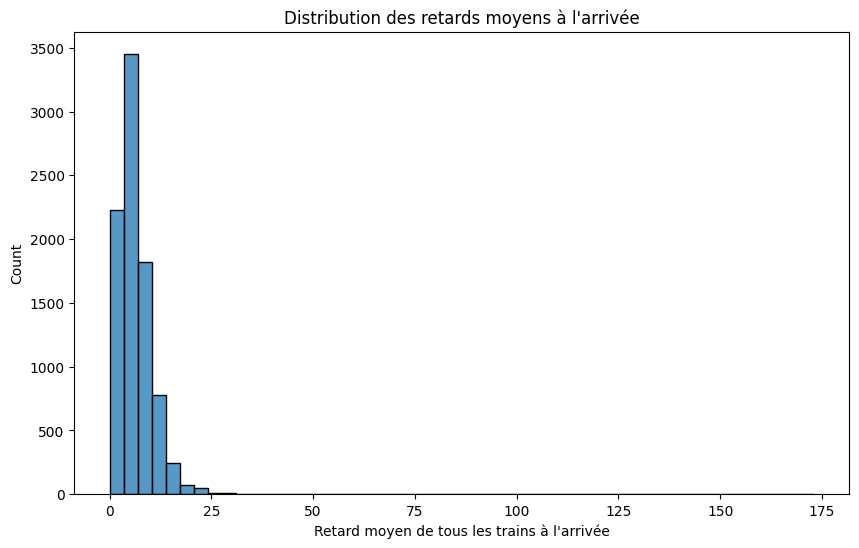

In [33]:
plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.histplot(data=df, x="Retard moyen de tous les trains à l'arrivée", bins=50) # Create a histogram using the dataframe df with the column "Retard moyen de tous les trains à l'arrivée" and dividing them into 50 intervals.
plt.title("Distribution des retards moyens à l'arrivée") # allows you to add a title to the graph



*We have created a graph showing the average delays for all trains by month, allowing us to
see peaks, but especially one that is really significant during the summer holidays.*

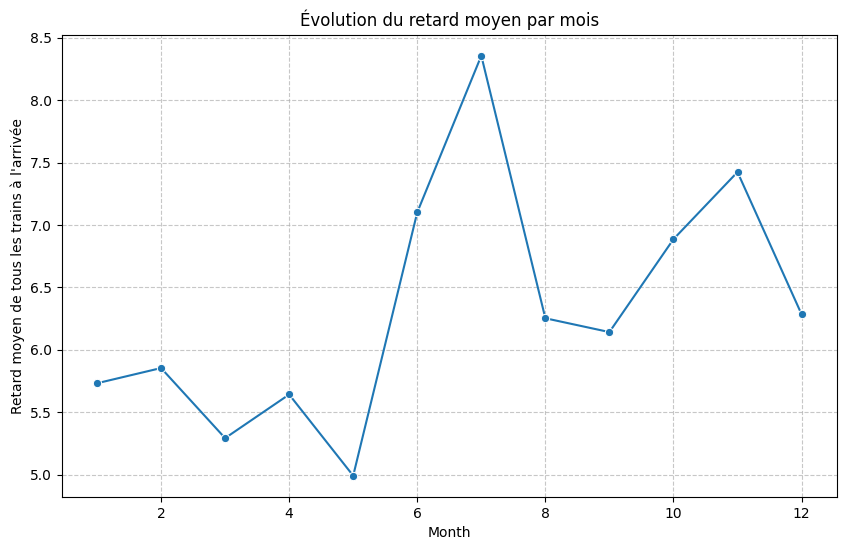

In [34]:
# on a crée une evolution des retards moyen de touts les trains en fonction des mois nous permettant
# de voir des pics mais surtout un qui est pour les grandes vacances vraiment gros
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")# change the column to datetime (for dates and times) and for errors they are replaced with missing values
df["Month"] = df["Date"].dt.month # creates a new Month column with the month extracted from each date


plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.lineplot(data=df, x="Month", y="Retard moyen de tous les trains à l'arrivée", estimator="mean", errorbar=None, marker="o") # creates a graph with seaborn with the variable of the month in x and in y the « Retard moyen de tous les trains à l'arrivée », this calculates the average for each month, the none function of error bar allows you not to display the error bars and marker=o allows you to put a round dot for each value
plt.title("Évolution du retard moyen par mois") # allows you to add a title to the graph
plt.grid(True, linestyle="--", alpha=0.7) # adding a grid to the graph linestyle defines the line type for the grid and alpha manages transparency



*graphics sur le top des différentes raison de retard des trains et son pourcentage moyen de chaque cause*

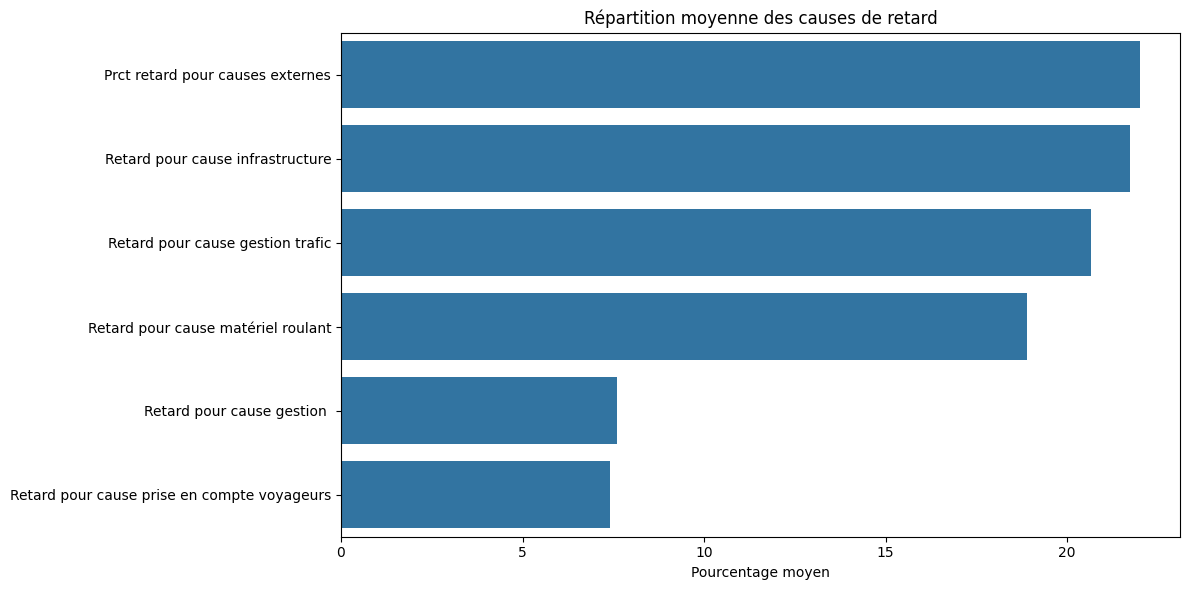

In [35]:
causes = [  # lists all causes of dataset delays
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
]
mean_causes = df[causes].mean().sort_values(ascending=False) # Select only the causes mentioned above, calculate the average of each column with mean() (each cause is a column) and output value. false sorts in descending order to create a top list. 

plt.figure(figsize=(12, 6)) # figure create a new drawing area and figsize changes the size of the drawing
sns.barplot(x=mean_causes.values, y=["Prct retard pour causes externes",
    "Retard pour cause infrastructure",
    "Retard pour cause gestion trafic",
    "Retard pour cause matériel roulant",
    "Retard pour cause gestion ",
    "Retard pour cause prise en compte voyageurs"]) # creates a bar chart with x and y: x = the numerical values of the average delays for each cause, y = the names of the causes

plt.title("Répartition moyenne des causes de retard") # allows you to add a title to the graph
plt.xlabel("Pourcentage moyen") # xlabel defines the x-axis of the graph, which is the average percentage
plt.tight_layout() # simply allows for a ‘compact’ layout, so that it looks better 


Text(0.5, 1.0, "Corrélation entre la durée du trajet et le retard moyen à l'arrivée")

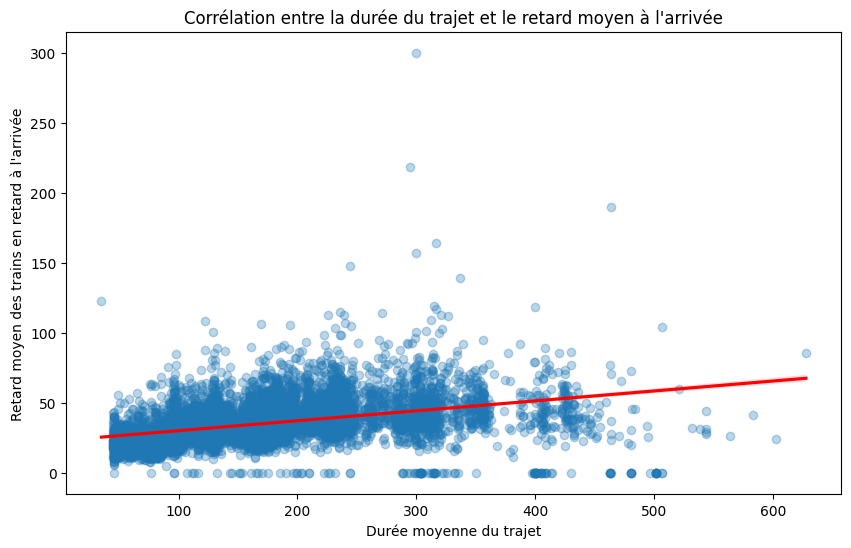

In [36]:
# de la moyenne de trajet et du retard moyen des trains en retard a l'arrivée et on peut voir
# que la kde augmente belle est bien et que donc il y a une coréllation"
plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.regplot( # This is how I create my scatter plot with the regression line. 
    data=df, # to use the dataframe 
    x="Durée moyenne du trajet", # select the "Durée moyenne du trajet" in x
    y="Retard moyen des trains en retard à l'arrivée", # select the "Retard moyen des trains en retard à l'arrivée" in y 
    scatter_kws={"alpha": 0.3}, # changes the regplot and alpha transparency parameters 
    line_kws={"color": "red"} # just allows you to change the colour of the kws line (the kws shows the link between the average journey time and the average delay of trains arriving late; if it is flat, there is no correlation, but if it rises or falls, there is a correlation)
)
plt.title("Corrélation entre la durée du trajet et le retard moyen à l'arrivée") # allows you to add a title to the graph


*afin de savoir pourquoi les trains etait en retard au au départ on a fait une correlation 
de la moyenne de trajet et du retard moyen des trains en retard a au depart et on peut voir
que la kde augmente belle est bien et que donc il y a une coréllation*

Text(0.5, 1.0, 'Corrélation entre la durée du trajet et le retard moyen au départ')

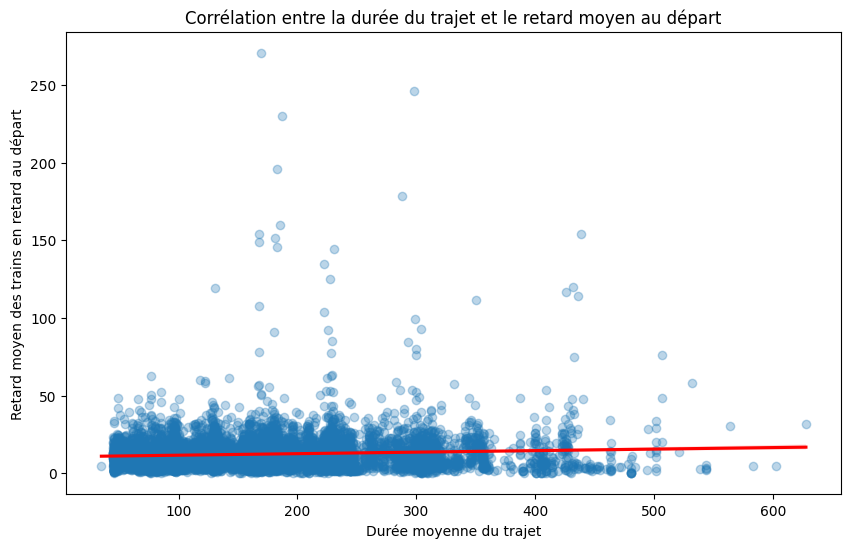

In [37]:

plt.figure(figsize=(10, 6))  # figure creates a new drawing area and figsize changes the size of the drawing  
sns.regplot( # This is how I create my scatter plot with the regression line.
    data=df, # to use the dataframe 
    x="Durée moyenne du trajet", # select the "Durée moyenne du trajet" in x
    y="Retard moyen des trains en retard au départ", # select the "Retard moyen des trains en retard au départ" in y 
    scatter_kws={"alpha": 0.3}, # changes the regplot and alpha transparency parameters 
    line_kws={"color": "red"} # just allows you to change the colour of the kws line (the kws shows the link between the average journey time and the average delay of trains arriving late; if it is flat, there is no correlation, but if it rises or falls, there is a correlation)
)
plt.title("Corrélation entre la durée du trajet et le retard moyen au départ") # allows you to add a title to the graph


/tmp/ipykernel_690814/1739471047.py:4: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout() # simply allows for a ‘compact’ layout, so that it looks better


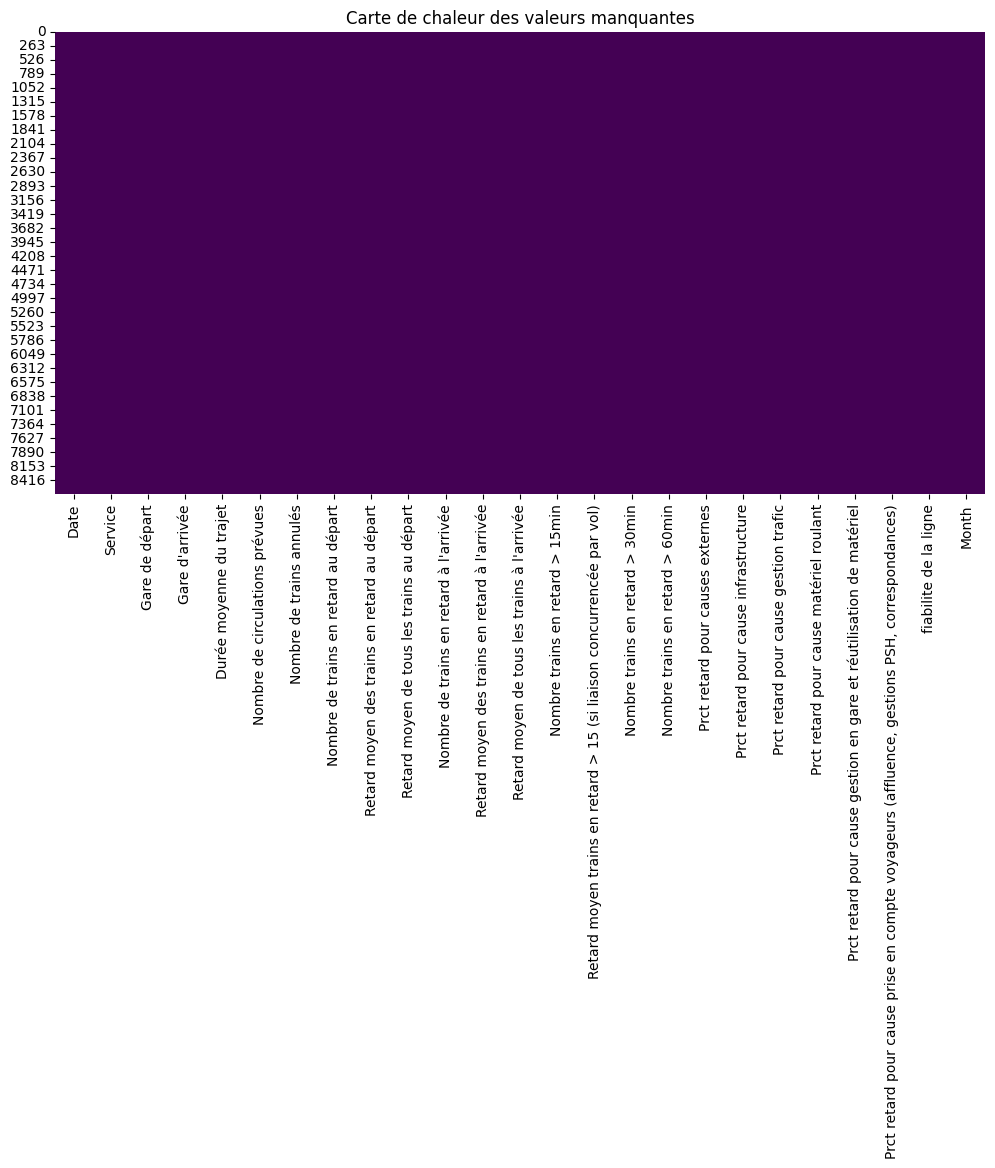

In [38]:


plt.figure(figsize=(12, 6)) # figure creates a new drawing area and figsize changes the size of the drawing  
sns.heatmap(df.isnull(), cbar=False, cmap="viridis") #  crée une heatmap avec seaborn, chaque valeur manquante : false = l'afficher sur la heatmap et ou précisément, cbar = false (pas de barre de couleur) et cmap virius permet de choisir la couler de la heatmap
plt.title("Carte de chaleur des valeurs manquantes") # allows you to add a title to the graph
plt.tight_layout() # simply allows for a ‘compact’ layout, so that it looks better 


Text(0.5, 1.0, "Détection des valeurs aberrantes (Outliers) - Retard à l'arrivée")

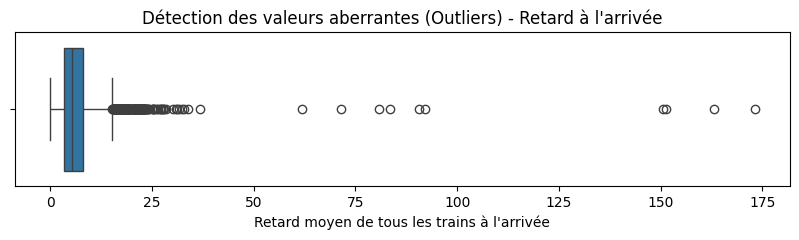

In [39]:
plt.figure(figsize=(10, 2)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.boxplot(data=df, x="Retard moyen de tous les trains à l'arrivée") # creates a box plot of the dataframe with x: "Retard moyen de tous les trains à l'arrivée"
plt.title("Détection des valeurs aberrantes (Outliers) - Retard à l'arrivée") # allows you to add a title to the graph


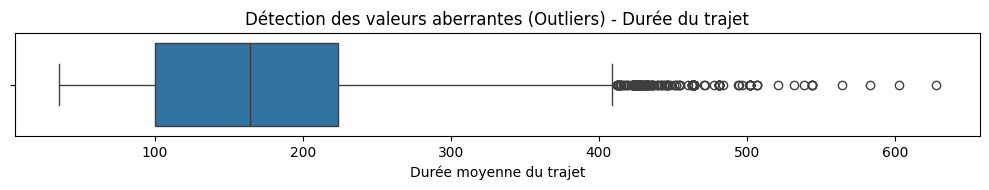

In [40]:

plt.figure(figsize=(10, 2)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.boxplot(data=df, x="Durée moyenne du trajet") # creates a box plot of the dataframe with x: "Durée moyenne du trajet"
plt.title("Détection des valeurs aberrantes (Outliers) - Durée du trajet") # allows you to add a title to the graph
plt.tight_layout()  # simply allows for a (compact) layout, so that it looks better 
